# 02 · Análisis exploratorio de datos (EDA)

**Proyecto semestral IMT2200, Grupo 5:** *¿Mide el NEM lo mismo para todos?*

**Entrada:** `data/processed/panel_completo.parquet` (de `01_carga_y_limpieza`).
**Salidas:** `data/processed/muestra.parquet` (para el modelamiento) y las figuras y
tablas en `imgs/`.

| Sección | Contenido |
|---|---|
| 1 | Calidad de datos y comparabilidad entre años |
| 2 | Muestra analítica y definición de la brecha |
| 3 | Sensibilidad a la prueba PAES elegida |
| 4 | Pregunta 1: ¿cómo se relacionan NEM y PAES? |
| 5 | Pregunta 2: brecha según dependencia y nivel socioeconómico |
| 6 | Nivel establecimiento (insumo para el modelo jerárquico) |
| 7 | Pregunta 3: brecha y etapas del acceso |
| 8 | Evolución 2023-2026 |
| 9 | Síntesis de hallazgos |

In [1]:
# Configuración: librerías, módulos del proyecto (src/) y carga del panel.
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Raíz del proyecto (funciona si el notebook se abre desde notebooks/ o
# desde la raíz) para poder importar los módulos de src/.
RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RAIZ))

# Los módulos de src/ se importan después de agregar la raíz al path; por
# eso llevan "noqa: E402" (PEP8 pide los imports al inicio del archivo).
from src.config import (ARCHIVO_MUESTRA, ARCHIVO_PANEL,  # noqa: E402
                        COLUMNAS_MUESTRA, DEPENDENCIA_ETIQUETAS, DIR_IMGS,
                        EGRESO_OFFSET, ELECTIVAS, MIN_ESTUDIANTES_COLEGIO,
                        MIN_N_CELDA, PRUEBAS_PAES)
from src.estadistica import (correlaciones_anio,  # noqa: E402
                             nulos_y_ceros, proporcion_varianza_entre,
                             resumen, tasas_acceso, v_de_cramer)
from src.graficos import (aplicar_estilo,  # noqa: E402
                          boxplot_por_dependencia, histogramas,
                          lineas_por_dependencia, mostrar)
from src.muestra import (agregar_variables, calcular_brechas,  # noqa: E402
                         construir_muestra, puntaje_valido)

aplicar_estilo()
panel_completo = pd.read_parquet(ARCHIVO_PANEL)
print(f'Panel: {len(panel_completo)} inscritos, '
      f'años {sorted(panel_completo["ANIO"].unique().tolist())}')

Panel: 1240008 inscritos, años [2023, 2024, 2025, 2026]


## 1. Calidad de datos y comparabilidad entre años

Se revisa que las variables signifiquen lo mismo en los cuatro procesos: faltantes,
ceros usados como "no rindió", códigos de dependencia y qué rendición usar.

In [2]:
# 1.a % de nulos y de ceros por año. Un % de ceros alto en un puntaje
# indica que 0 significa "no rindió" (se trata como faltante).
COLUMNAS_CALIDAD: list[str] = [
    'ANYO_DE_EGRESO', 'PROMEDIO_NOTAS', 'PTJE_NEM', 'CLEC_REG_ACTUAL',
    'MATE1_REG_ACTUAL', 'HCSOC_REG_ACTUAL', 'CIEN_REG_ACTUAL', 'DEPENDENCIA',
    'INGRESO_PERCAPITA_GRUPO_FA',
]
display(nulos_y_ceros(panel_completo, COLUMNAS_CALIDAD))

,2023,2024,2025,2026
ANYO_DE_EGRESO (% nulos),0.1,0.1,0.0,0.1
ANYO_DE_EGRESO (% ceros),0.0,0.0,0.0,0.0
PROMEDIO_NOTAS (% nulos),0.0,0.0,0.0,0.0
PROMEDIO_NOTAS (% ceros),1.5,1.7,1.7,1.9
PTJE_NEM (% nulos),0.0,0.0,0.0,0.0
PTJE_NEM (% ceros),1.5,1.7,1.7,1.9
CLEC_REG_ACTUAL (% nulos),7.3,7.0,6.3,6.1
CLEC_REG_ACTUAL (% ceros),12.9,13.7,14.0,15.5
MATE1_REG_ACTUAL (% nulos),7.3,7.0,6.3,6.1
MATE1_REG_ACTUAL (% ceros),13.3,14.3,15.6,17.1


In [3]:
# 1.b Inscritos por dependencia y año: los códigos son los mismos en los
# 4 procesos y SLEP crece por los traspasos desde municipios.
dependencia = panel_completo['DEPENDENCIA'].map(DEPENDENCIA_ETIQUETAS)
display(pd.crosstab(dependencia.fillna('Sin dato'), panel_completo['ANIO']))

ANIO,2023,2024,2025,2026
DEPENDENCIA,,,,
Adm. delegada,9948,10455,10524,10571
Municipal,82675,84174,82595,68465
Part. pagado,31555,32448,33584,35248
Part. subvencionado,158468,164257,165980,168231
SLEP,11508,13084,15974,34372
Sin dato,2658,4932,5102,3200


In [4]:
# 1.c ¿Cuál es la "primera rendición"? Entre egresados recientes, cuántos
# rindieron cada prueba solo en diciembre (REG), solo en junio (INV), en
# ambas, o en el proceso anterior. Si casi nadie rinde INV ni el proceso
# anterior, la primera rendición es en la práctica la regular.
recientes = panel_completo[panel_completo['ANYO_DE_EGRESO']
                           == panel_completo['ANIO'] - EGRESO_OFFSET]
filas = []
for prueba in PRUEBAS_PAES:
    reg = puntaje_valido(recientes[f'{prueba}_REG_ACTUAL'])
    inv = puntaje_valido(recientes[f'{prueba}_INV_ACTUAL'])
    ant = (puntaje_valido(recientes[f'{prueba}_REG_ANTERIOR'])
           | puntaje_valido(recientes[f'{prueba}_INV_ANTERIOR']))
    conteo = pd.DataFrame({'solo_REG': reg & ~inv, 'solo_INV': inv & ~reg,
                           'REG_e_INV': reg & inv, 'proceso_anterior': ant})
    tabla = conteo.groupby(recientes['ANIO']).sum()
    tabla.insert(0, 'prueba', PRUEBAS_PAES[prueba])
    filas.append(tabla)
print(f'Egresados recientes: {len(recientes)} (4 años)')
display(pd.concat(filas).reset_index().set_index(['prueba', 'ANIO']))

Egresados recientes: 835424 (4 años)


solo_REG  solo_INV  REG_e_INV  proceso_anterior
prueba                  ANIO                                                 
Comp. Lectora           2023    171953         8         21                49
                        2024    177313         9         16                45
                        2025    181104         0          0                34
                        2026    185231         0          0                51
Matemática 1            2023    169573         0          0                 0
                        2024    174766         8         16                42
                        2025    178235         0          0                30
                        2026    182045         0          0                45
Historia y Cs. Sociales 2023     94832         5          7                30
                        2024    101391         2          5                25
                        2025    101894         0          0                19
                        2026    100082         0          0                29
Ciencias                2023    115875         5         16                19
                        2024    120483         7         11                28
                        2025    126309         0          0                16
                        2026    126637         0          0                27

## 2. Muestra analítica y definición de la brecha

**Muestra:** egresados del año anterior al proceso, con NEM válido, que rindieron al
menos una electiva y que cursaron **educación regular (niños y jóvenes) en un
establecimiento identificado**; se excluye la validación y el reconocimiento de
estudios, la educación de adultos y el RBD 99999. Hay tres grupos de electiva: solo
Ciencias, solo Historia y **Ambas** (PAES electiva = promedio de las dos). Cada
estudiante se compara solo con su grupo.

**Brechas** (en desviaciones estándar, DE, dentro de cada año y electiva):

- **Brecha condicional (medida principal):** NEM observado menos el NEM esperado para
  la PAES del estudiante (residuo de una regresión de `NEM_z` sobre `PAES_z`).
  Responde *"a igual PAES, ¿distinto NEM?"*.
- **Brecha simple** `NEM_z - PAES_z`: solo como comparación (5.e), porque mezcla
  diferencias reales con regresión a la media.

Ambas tienen media 0 en cada año y grupo: lo comparable son las diferencias entre
grupos (dependencia, decil, colegio).

In [5]:
# 2.a Muestra analítica: embudo de filtros por año (src/muestra.py).
muestra, embudo = construir_muestra(panel_completo)
display(embudo)
print(f'Muestra analítica: {len(muestra)} estudiantes en 4 años.')
print(muestra['electiva'].value_counts().to_string())

ANIO,2023,2024,2025,2026
Inscritos,296812,309350,313759,320087
Egresado reciente,198374,205547,211404,220099
+ NEM válido,194715,201146,207081,215145
+ rindió electiva,166803,169807,172067,173256
+ educación regular en establecimiento identificado,160021,162449,164981,166691


Muestra analítica: 654142 estudiantes en 4 años.
electiva
Ciencias    278579
Ambas       191484
Historia    184079


In [6]:
# 2.b Brechas y variables explicativas con etiquetas (src/muestra.py).
muestra = agregar_variables(calcular_brechas(muestra))
print('Muestra por dependencia (%):')
print((100 * muestra['dependencia'].value_counts(normalize=True, sort=False))
      .round(1).to_string())
no_responde = (muestra['decil'] == 'No responde').mean()
print(f'No responde ingreso: {no_responde:.1%}')

Muestra por dependencia (%):
dependencia
Municipal              25.1
SLEP                    5.7
Part. subvencionado    53.5
Adm. delegada           3.2
Part. pagado           12.4
No responde ingreso: 25.9%


## 3. Sensibilidad a la prueba PAES elegida

¿La electiva es una buena referencia frente a Competencia Lectora o Matemática 1? Si
las tres versiones de la brecha ordenan igual a las dependencias, la elección no
cambia las conclusiones.

In [7]:
# 3.a Cobertura de cada prueba y correlación de NEM con cada una, por año.
cobertura = muestra[['CLEC_1ra', 'MATE1_1ra', 'PAES_electiva']].notna().mean()
print('Cobertura dentro de la muestra (%):')
print((100 * cobertura).round(1).to_string())

filas = {}
for anio, grupo in muestra.groupby('ANIO'):
    filas[anio] = correlaciones_anio(grupo)
print('\nCorrelación de Pearson entre NEM y cada prueba:')
display(pd.DataFrame(filas).T.round(3))

Cobertura dentro de la muestra (%):
CLEC_1ra          99.4
MATE1_1ra         98.8
PAES_electiva    100.0



Correlación de Pearson entre NEM y cada prueba:


,NEM~Lectora,NEM~M1,NEM~Ciencias,NEM~Historia,NEM~Ambas
2023,0.564,0.491,0.567,0.501,0.488
2024,0.529,0.519,0.571,0.506,0.482
2025,0.537,0.537,0.576,0.508,0.493
2026,0.549,0.527,0.562,0.491,0.484


,Electiva,Lectora,Matemática 1,Electiva condicional
dependencia,,,,
Municipal,0.166,0.173,0.199,0.045
SLEP,0.300,0.311,0.339,0.120
Part. subvencionado,0.005,-0.041,-0.003,-0.025
Adm. delegada,0.099,0.094,0.062,-0.126
Part. pagado,-0.521,-0.336,-0.550,-0.005


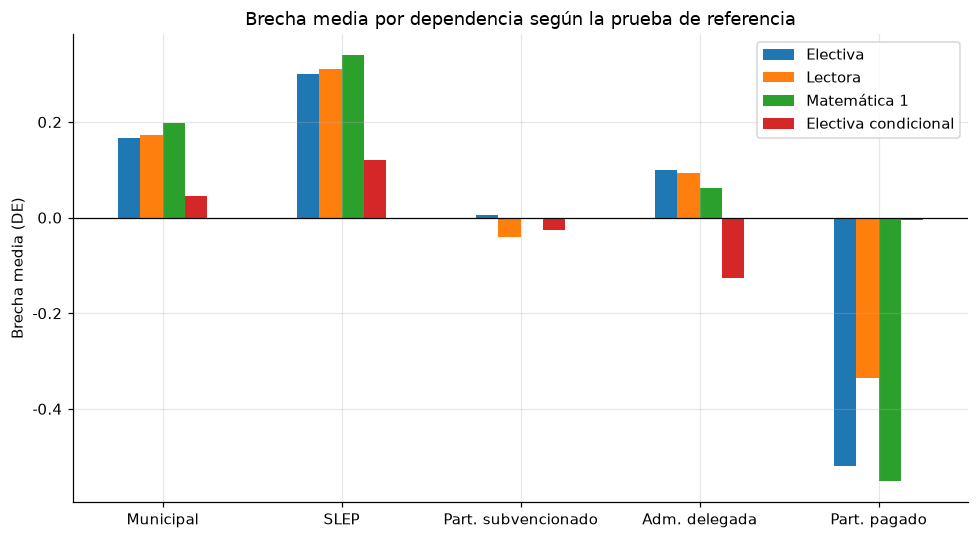

In [8]:
# 3.b Brecha media por dependencia según la prueba de referencia.
versiones = {'brecha': 'Electiva', 'brecha_CLEC': 'Lectora',
             'brecha_MATE1': 'Matemática 1',
             'brecha_cond': 'Electiva condicional'}
medias = (muestra.groupby('dependencia', observed=True)[list(versiones)]
          .mean().rename(columns=versiones))
display(medias.round(3))

ax = medias.plot(kind='bar', rot=0)
ax.axhline(0, color='black', linewidth=0.8)
ax.set(title='Brecha media por dependencia según la prueba de referencia',
       xlabel='', ylabel='Brecha media (DE)')
plt.tight_layout()
mostrar('eda_3b')

## 4. Pregunta 1: ¿cómo se relacionan el NEM y la PAES?

In [9]:
# 4.a Media y desviación estándar de NEM y PAES electiva por año.
display(muestra.groupby('ANIO')[['PTJE_NEM', 'PAES_electiva']]
        .agg(['mean', 'std']).round(1))

PTJE_NEM        PAES_electiva       
         mean    std          mean    std
ANIO                                     
2023    723.0  143.3         502.4  107.6
2024    730.7  144.1         487.5  115.2
2025    731.2  139.7         489.1  125.0
2026    738.0  138.9         484.4  123.5

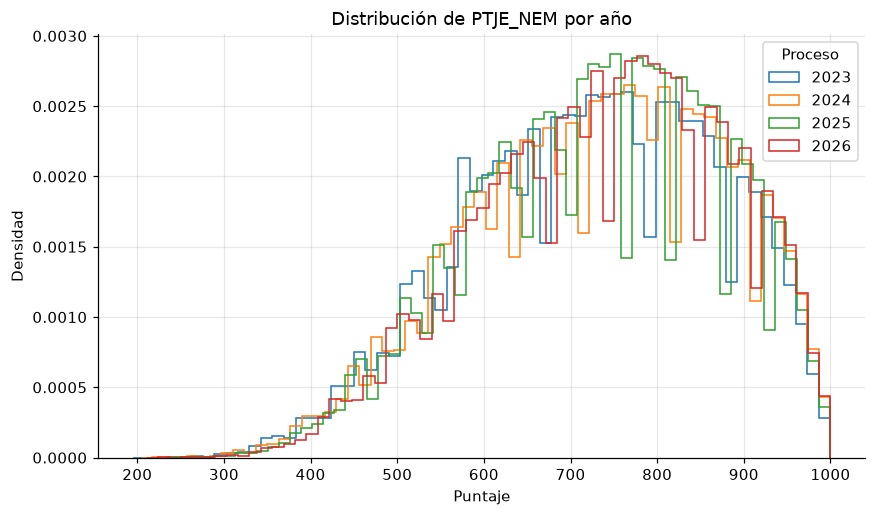

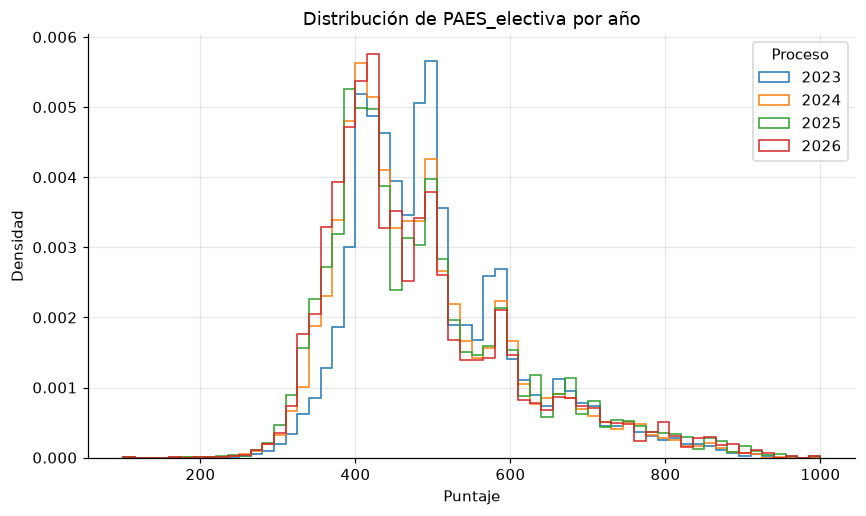

In [10]:
# 4.b Distribución de NEM y de la PAES electiva, una curva por año.
for columna, nombre in [('PTJE_NEM', 'nem'), ('PAES_electiva', 'paes')]:
    fig, ax = plt.subplots()
    histogramas(ax, muestra, columna, 'ANIO')
    ax.set(title=f'Distribución de {columna} por año', xlabel='Puntaje')
    ax.legend(title='Proceso')
    mostrar(f'eda_4b_{nombre}')

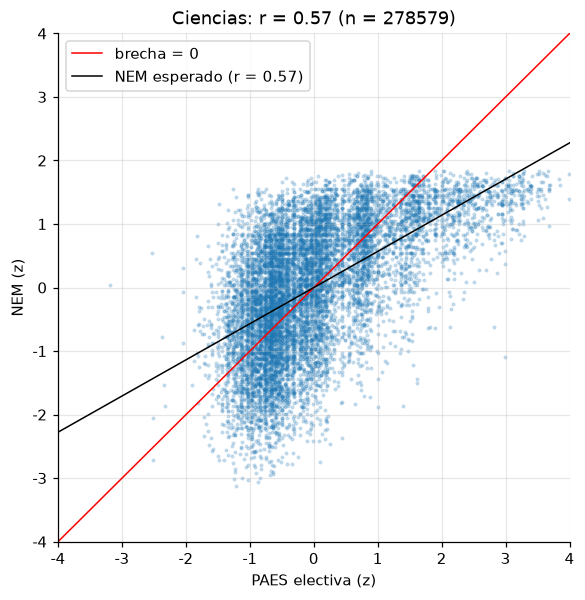

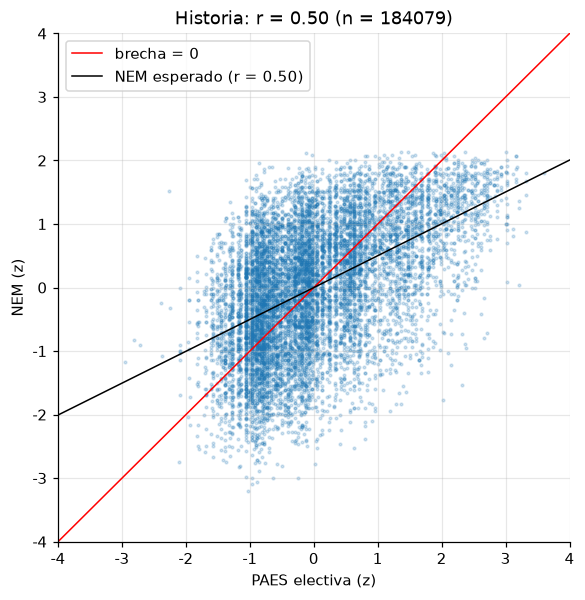

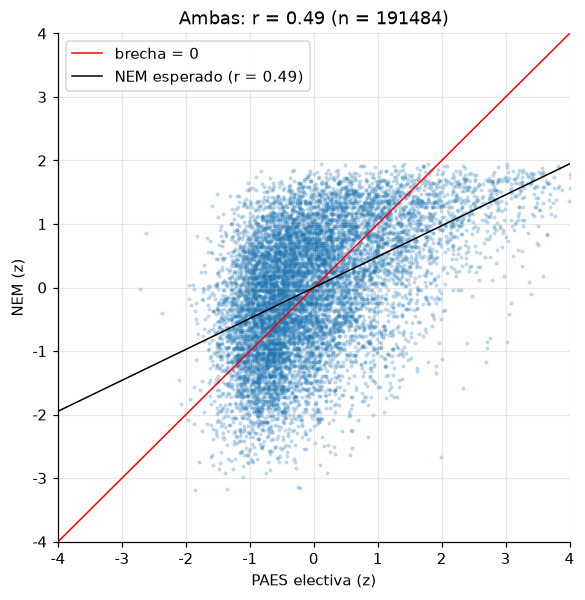

In [11]:
# 4.c NEM_z vs PAES_z por electiva (submuestra de 10 mil puntos). Sobre la
# diagonal roja la brecha simple es 0. La línea negra es el NEM esperado
# dada la PAES (r * PAES_z): es más plana por la regresión a la media.
for electiva in ELECTIVAS:
    datos = muestra[muestra['electiva'] == electiva]
    r = datos['NEM_z'].corr(datos['PAES_z'])
    sub = datos.sample(n=10_000, random_state=2026)

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(sub['PAES_z'], sub['NEM_z'], s=3, alpha=0.2)
    ax.plot([-4, 4], [-4, 4], color='red', linewidth=1, label='brecha = 0')
    ax.plot([-4, 4], [-4 * r, 4 * r], color='black', linewidth=1,
            label=f'NEM esperado (r = {r:.2f})')
    ax.set(title=f'{electiva}: r = {r:.2f} (n = {len(datos)})',
           xlabel='PAES electiva (z)', ylabel='NEM (z)',
           xlim=(-4, 4), ylim=(-4, 4))
    ax.legend(loc='upper left')
    mostrar(f'eda_4c_{electiva.lower()}')

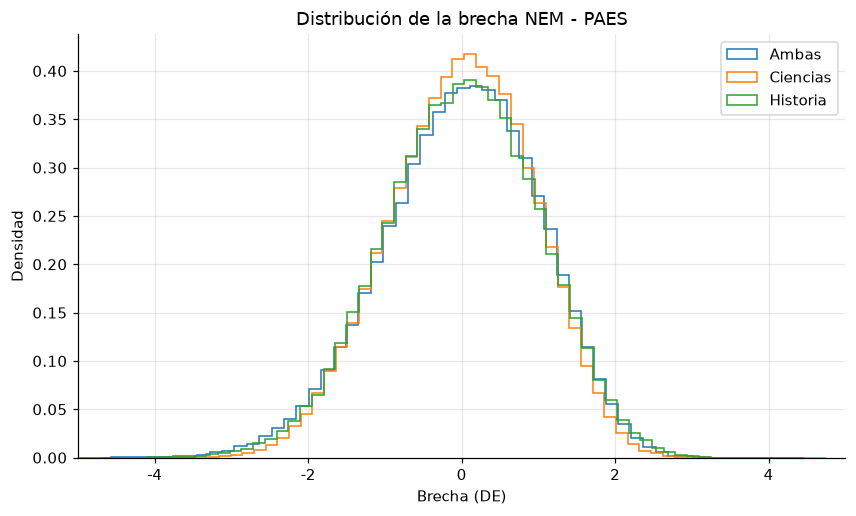

brecha > 1 DE: 15.6% | brecha < -1 DE: 15.7%


In [12]:
# 4.d Distribución de la brecha simple y % de brechas grandes.
fig, ax = plt.subplots()
histogramas(ax, muestra, 'brecha', 'electiva')
ax.set(title='Distribución de la brecha NEM - PAES', xlabel='Brecha (DE)',
       xlim=(-5, 5))
ax.legend()
mostrar('eda_4d')
print(f"brecha > 1 DE: {(muestra['brecha'] > 1).mean():.1%} | "
      f"brecha < -1 DE: {(muestra['brecha'] < -1).mean():.1%}")

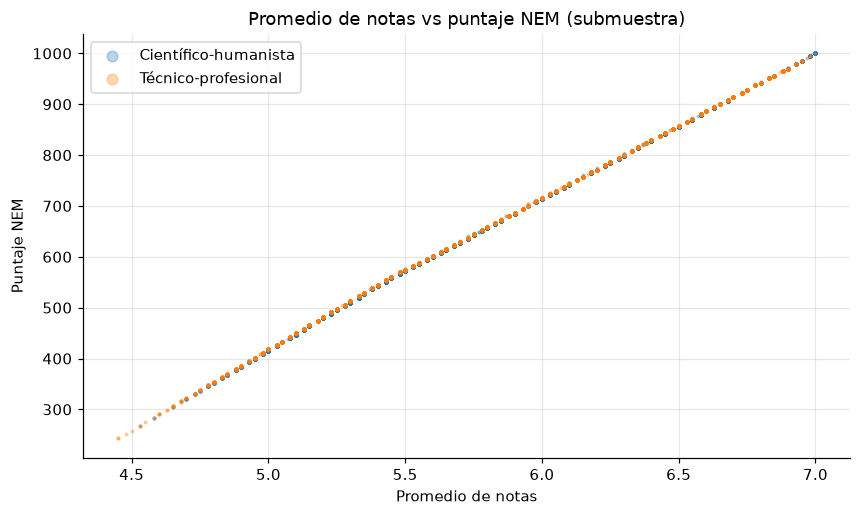

In [13]:
# 4.e Promedio de notas vs puntaje NEM según modalidad (submuestra). Si
# las nubes coinciden, la conversión a NEM es la misma en HC y TP.
sub = muestra.sample(n=30_000, random_state=2026)
fig, ax = plt.subplots()
for modalidad, grupo in sub.groupby('modalidad'):
    ax.scatter(grupo['PROMEDIO_NOTAS'], grupo['PTJE_NEM'], s=3, alpha=0.3,
               label=modalidad)
ax.set(title='Promedio de notas vs puntaje NEM (submuestra)',
       xlabel='Promedio de notas', ylabel='Puntaje NEM')
ax.legend(markerscale=4)
mostrar('eda_4e')

## 5. Pregunta 2: brecha según dependencia y nivel socioeconómico

Desde aquí la medida principal es la **brecha condicional** (`brecha_cond`). Se
muestran también sus componentes (NEM_z y PAES_z) para ver de dónde viene cada
diferencia. La sección 5.e la compara con la brecha simple.

,n,media,de,ic95_inf,ic95_sup
dependencia,,,,,
Municipal,164087,0.045,0.890,0.041,0.049
SLEP,37375,0.120,0.881,0.111,0.129
Part. subvencionado,350115,-0.025,0.858,-0.028,-0.022
Adm. delegada,21187,-0.126,0.917,-0.138,-0.114
Part. pagado,81378,-0.005,0.668,-0.010,-0.000


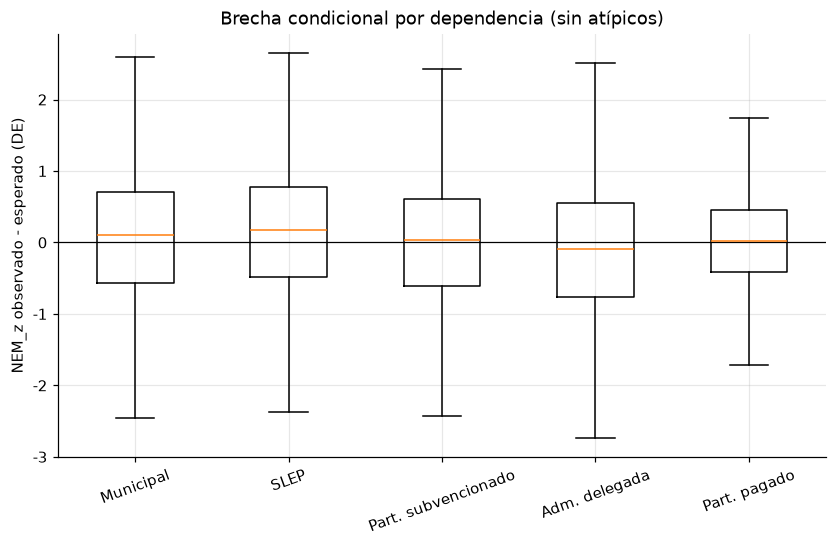

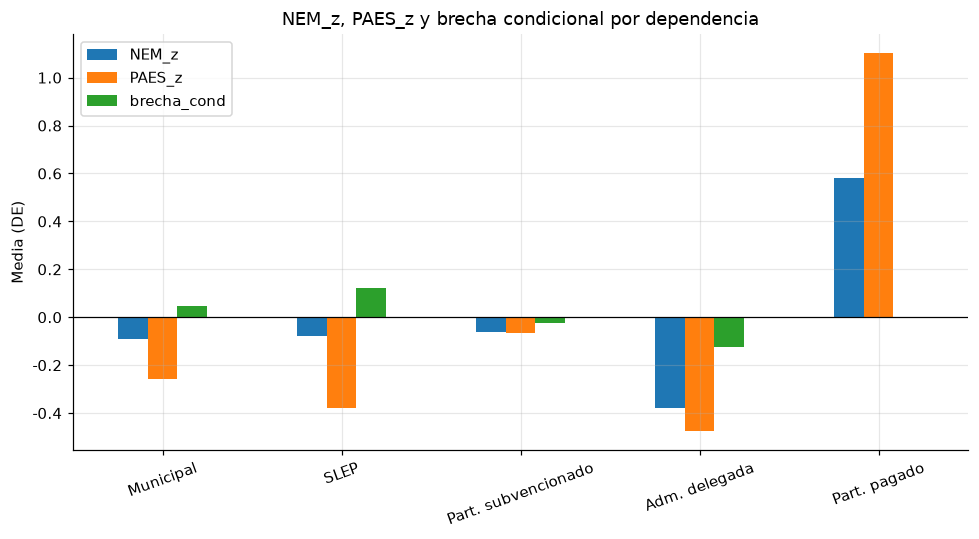

In [14]:
# 5.a Brecha condicional por dependencia: tabla, boxplot y componentes.
display(resumen(muestra, 'dependencia', 'brecha_cond'))

fig, ax = plt.subplots()
boxplot_por_dependencia(ax, muestra, 'brecha_cond')
ax.set(title='Brecha condicional por dependencia (sin atípicos)',
       ylabel='NEM_z observado - esperado (DE)')
mostrar('eda_5a_boxplot')

componentes = muestra.groupby('dependencia', observed=True)[
    ['NEM_z', 'PAES_z', 'brecha_cond']].mean()
ax = componentes.plot(kind='bar', rot=20)
ax.axhline(0, color='black', linewidth=0.8)
ax.set(title='NEM_z, PAES_z y brecha condicional por dependencia',
       xlabel='', ylabel='Media (DE)')
plt.tight_layout()
mostrar('eda_5a_componentes')

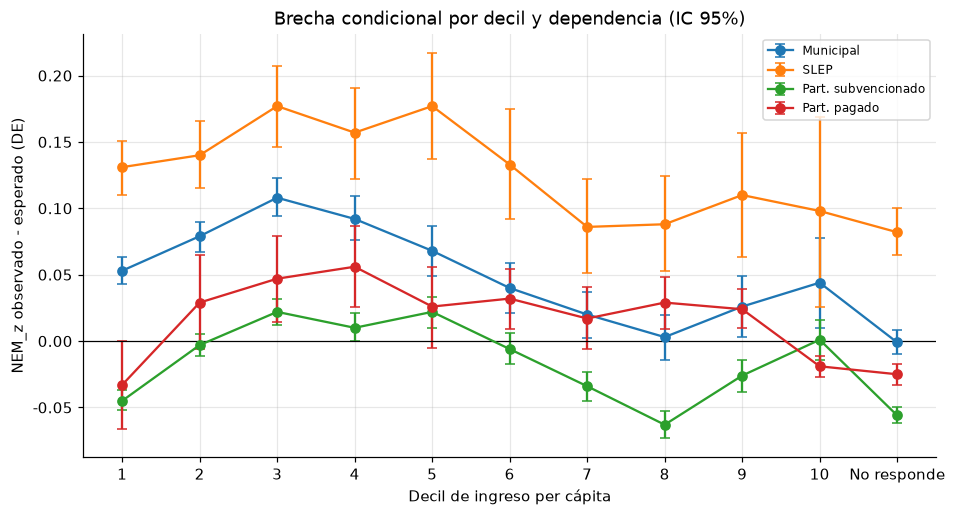

In [15]:
# 5.b Brecha condicional por decil, una línea por dependencia, con IC 95%
# (las diferencias son pequeñas; el IC muestra cuáles se distinguen de 0).
fig, ax = plt.subplots(figsize=(10, 5))
lineas_por_dependencia(ax, muestra, 'decil', 'brecha_cond', con_ic=True)
ax.axhline(0, color='black', linewidth=0.8)
ax.set(title='Brecha condicional por decil y dependencia (IC 95%)',
       xlabel='Decil de ingreso per cápita',
       ylabel='NEM_z observado - esperado (DE)')
mostrar('eda_5b')

In [16]:
# 5.c Tabla dependencia x decil con la brecha condicional media (se ocultan
# las celdas con menos de MIN_N_CELDA estudiantes; rojo = positiva, azul =
# negativa). Se guarda como CSV en imgs/ para el informe.
tabla_media = muestra.pivot_table(index='dependencia', columns='decil',
                                  values='brecha_cond', aggfunc='mean',
                                  observed=True)
tabla_n = muestra.pivot_table(index='dependencia', columns='decil',
                              values='brecha_cond', aggfunc='count',
                              observed=True)
tabla_media = tabla_media.where(tabla_n >= MIN_N_CELDA).round(3)

limite = tabla_media.abs().max().max()
display(tabla_media.style
        .background_gradient(cmap='RdBu_r', vmin=-limite, vmax=limite,
                             axis=None)
        .format('{:.2f}', na_rep=''))
tabla_media.to_csv(DIR_IMGS / 'eda_5c_brecha_cond_dependencia_decil.csv',
                   sep=';', decimal=',')

decil,1,2,3,4,5,6,7,8,9,10,No responde
dependencia,,,,,,,,,,,
Municipal,0.05,0.08,0.11,0.09,0.07,0.04,0.02,0.00,0.03,0.04,-0.00
SLEP,0.13,0.14,0.18,0.16,0.18,0.13,0.09,0.09,0.11,0.10,0.08
Part. subvencionado,-0.04,-0.00,0.02,0.01,0.02,-0.01,-0.03,-0.06,-0.03,0.00,-0.06
Adm. delegada,-0.16,-0.10,-0.09,-0.07,-0.10,-0.13,-0.13,-0.20,-0.14,-0.03,-0.12
Part. pagado,-0.03,0.03,0.05,0.06,0.03,0.03,0.02,0.03,0.02,-0.02,-0.03


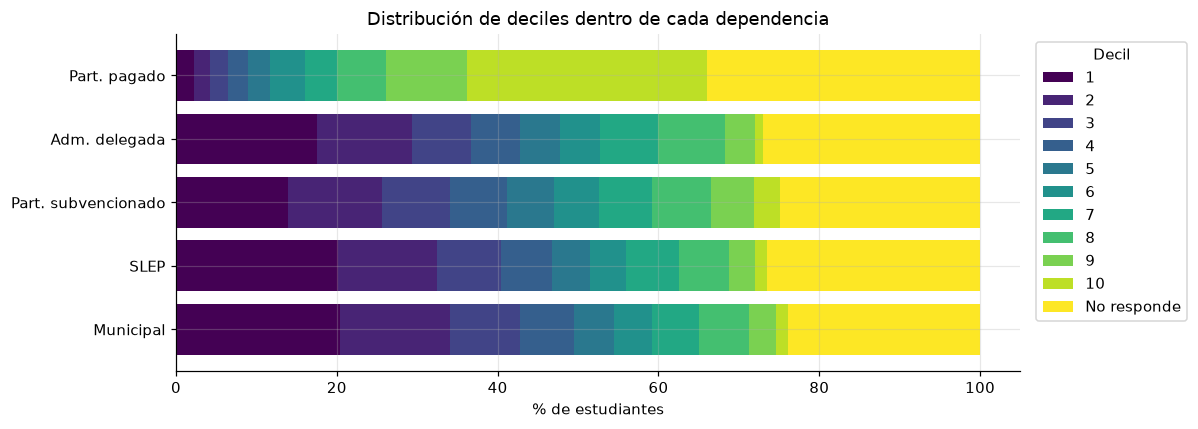

V de Cramér dependencia x decil (sin no respuesta): 0.265


In [17]:
# 5.d Composición socioeconómica de cada dependencia y su asociación
# (V de Cramér): anticipa la colinealidad que luego medirá el VIF.
composicion = pd.crosstab(muestra['dependencia'], muestra['decil'],
                          normalize='index')
ax = (100 * composicion).plot(kind='barh', stacked=True, figsize=(11, 4),
                              colormap='viridis', width=0.8)
ax.set(title='Distribución de deciles dentro de cada dependencia',
       xlabel='% de estudiantes', ylabel='')
ax.legend(title='Decil', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
mostrar('eda_5d')

declaran = muestra[muestra['decil'] != 'No responde']
v = v_de_cramer(pd.crosstab(declaran['dependencia'],
                            declaran['decil'].astype(str)))
print(f'V de Cramér dependencia x decil (sin no respuesta): {v:.3f}')

### ¿Por qué la brecha condicional es la medida principal?

**Regresión a la media.** El NEM y la PAES están relacionados, pero no de forma
perfecta (su correlación es cercana a 0,5). Cuando dos medidas se relacionan así,
quien tiene un valor muy alto en una suele tener un valor alto en la otra, pero
**menos extremo**. Es lo mismo que pasa con la estatura: los hijos de padres muy
altos suelen ser altos, pero en promedio menos que sus padres.

**El problema de la brecha simple.** La brecha simple (`NEM_z - PAES_z`) resta las
dos posiciones directamente. Por la regresión a la media, cualquier grupo con PAES
alta tendrá en promedio una brecha simple negativa, y cualquier grupo con PAES baja
una positiva, **aunque el NEM funcione exactamente igual para todos**.

**Ejemplo: Part. pagado.** Sus estudiantes tienen en promedio PAES_z = +1,10. Con una
correlación cercana a 0,5, el NEM esperado para *cualquier* estudiante con esa PAES
es cercano a +0,58, y el NEM real de Part. pagado es +0,58: justo el esperado. Aun
así, la brecha simple da **-0,52**, como si sus notas estuvieran "desinfladas". La
brecha condicional da **0,00**: a igual PAES, sus estudiantes tienen el mismo NEM que
el resto.

**Por qué responde mejor la pregunta.** La pregunta del proyecto es *"a igual PAES,
¿distinto NEM?"*, y la brecha condicional compara el NEM de cada estudiante con el
de otros que obtuvieron la misma PAES. Es la misma idea del modelo jerárquico
propuesto (`NEM_z ~ PAES_z + ...`).

### 5.e Comparación entre la brecha simple y la condicional

Por dependencia, modalidad y sexo (5.e.1), por decil (5.e.2, comparar con 5.b) y el
techo del NEM (5.e.3: promedio 7,0 = 1000 puntos).

,n,NEM_z,PAES_z,brecha_simple,brecha_condicional
dependencia,,,,,
Municipal,164087,-0.090,-0.256,0.166,0.045
SLEP,37375,-0.078,-0.378,0.300,0.120
Part. subvencionado,350115,-0.062,-0.067,0.005,-0.025
Adm. delegada,21187,-0.377,-0.476,0.099,-0.126
Part. pagado,81378,0.582,1.103,-0.521,-0.005


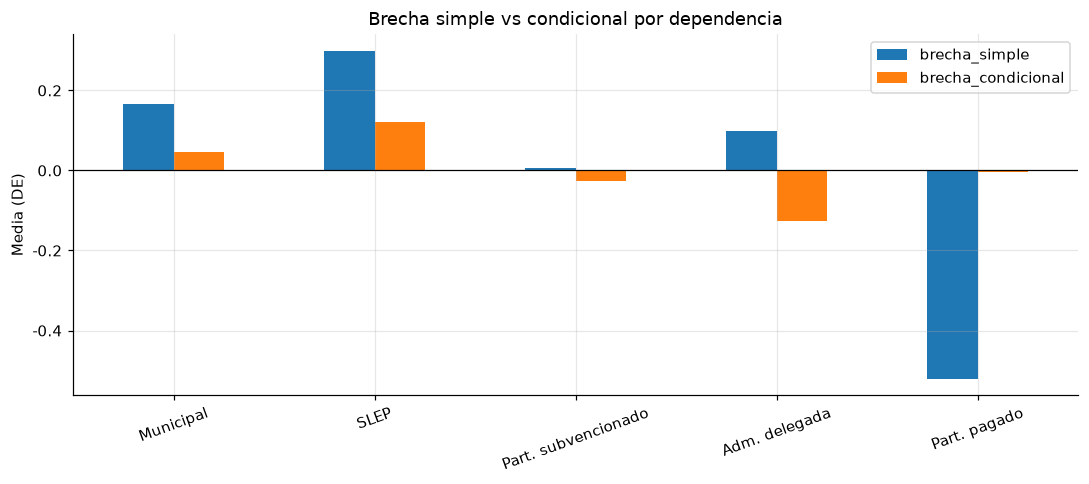

,NEM_z,PAES_z,brecha,brecha_cond
modalidad,,,,
Científico-humanista,0.113,0.181,-0.068,0.018
Técnico-profesional,-0.331,-0.531,0.200,-0.052


,NEM_z,PAES_z,brecha,brecha_cond
sexo,,,,
Hombre,-0.160,0.077,-0.237,-0.201
Mujer,0.141,-0.068,0.208,0.177


In [18]:
# 5.e.1 Brecha simple vs condicional por dependencia, modalidad y sexo.
comparacion = muestra.groupby('dependencia', observed=True).agg(
    n=('brecha', 'size'),
    NEM_z=('NEM_z', 'mean'),
    PAES_z=('PAES_z', 'mean'),
    brecha_simple=('brecha', 'mean'),
    brecha_condicional=('brecha_cond', 'mean'),
)
display(comparacion.round(3))

ax = comparacion[['brecha_simple', 'brecha_condicional']].plot(
    kind='bar', rot=20, figsize=(10, 4.5))
ax.axhline(0, color='black', linewidth=0.8)
ax.set(title='Brecha simple vs condicional por dependencia', xlabel='',
       ylabel='Media (DE)')
plt.tight_layout()
mostrar('eda_5e1')

for variable in ['modalidad', 'sexo']:
    display(muestra.groupby(variable)[['NEM_z', 'PAES_z', 'brecha',
                                       'brecha_cond']].mean().round(3))

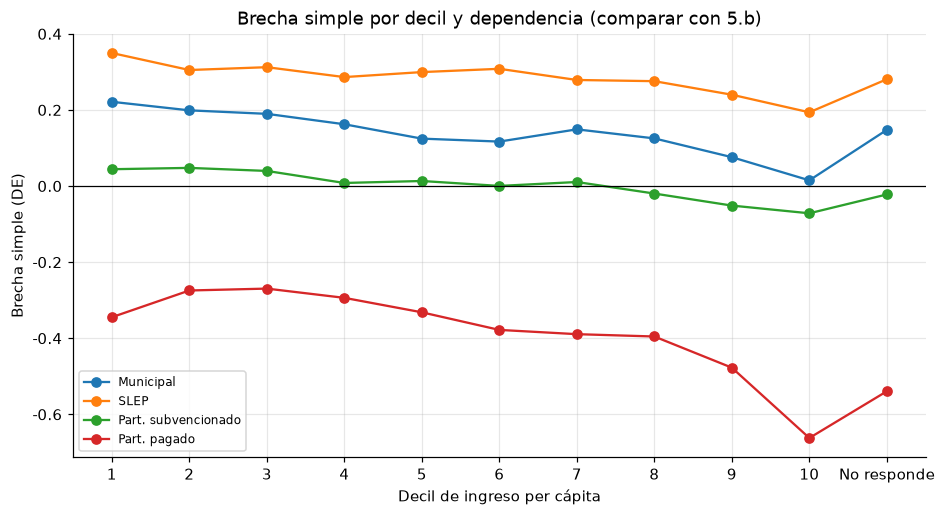

In [19]:
# 5.e.2 Brecha SIMPLE por decil y dependencia. Comparar con 5.b: el
# gradiente por decil casi desaparece en la brecha condicional.
fig, ax = plt.subplots(figsize=(10, 5))
lineas_por_dependencia(ax, muestra, 'decil', 'brecha')
ax.axhline(0, color='black', linewidth=0.8)
ax.set(title='Brecha simple por decil y dependencia (comparar con 5.b)',
       xlabel='Decil de ingreso per cápita', ylabel='Brecha simple (DE)')
mostrar('eda_5e2')

In [20]:
# 5.e.3 Techo del NEM: % con el NEM máximo, por dependencia y tercil de
# PAES. Si fuera alto, la brecha de quienes tienen PAES alta estaría acotada.
# La columna vale 100 si tiene el NEM máximo y 0 si no: su media es un %.
muestra['nem_en_techo'] = 100 * (muestra['PTJE_NEM']
                                 >= muestra['PTJE_NEM'].max())
muestra['tercil_paes'] = pd.qcut(muestra['PAES_z'], 3,
                                 labels=['PAES baja', 'PAES media',
                                         'PAES alta'])
print(f"% con NEM máximo (total): {muestra['nem_en_techo'].mean():.1f}%")
display(muestra.pivot_table(index='dependencia', columns='tercil_paes',
                            values='nem_en_techo', aggfunc='mean',
                            observed=True).round(1))

% con NEM máximo (total): 0.2%


tercil_paes,PAES baja,PAES media,PAES alta
dependencia,,,
Municipal,0.0,0.0,0.5
SLEP,0.0,0.1,0.6
Part. subvencionado,0.0,0.0,0.5
Adm. delegada,0.0,0.0,0.2
Part. pagado,0.0,0.0,0.9


## 6. Nivel establecimiento (insumo para el modelo jerárquico)

Estudiantes (nivel 1) dentro de establecimientos (nivel 2, `RBD`). Se mide qué parte
de la variación ocurre *entre* colegios con la **proporción de varianza entre
colegios** (varianza de los promedios de cada colegio sobre la varianza total), una
versión simple del ICC que lo sobreestima levemente; el ICC exacto saldrá del
modelo jerárquico.

In [21]:
# 6.a Un registro por colegio (4 años juntos). La dependencia del colegio
# es la del año más reciente (si hubo traspaso, la administración actual).
colegios = muestra.groupby('RBD').agg(
    n=('brecha_cond', 'size'),
    brecha_cond_media=('brecha_cond', 'mean'),
    decil_medio=('decil_num', 'mean'),
    n_dependencias=('DEPENDENCIA', 'nunique'),
)
ultima = (muestra.sort_values('ANIO')
          .drop_duplicates(subset='RBD', keep='last')
          .set_index('RBD')['dependencia'])
colegios['dependencia'] = ultima

print(f"Establecimientos: {len(colegios)} (mediana de "
      f"{colegios['n'].median():.0f} estudiantes)")
print(f"Con al menos {MIN_ESTUDIANTES_COLEGIO} estudiantes: "
      f"{(colegios['n'] >= MIN_ESTUDIANTES_COLEGIO).sum()}")
print(f"Cambian de dependencia en el periodo: "
      f"{(colegios['n_dependencias'] > 1).sum()}")

Establecimientos: 3034 (mediana de 171 estudiantes)
Con al menos 10 estudiantes: 2980
Cambian de dependencia en el periodo: 202


In [22]:
# 6.b Proporción de varianza entre colegios, por año y con los 4 años.
VARIABLES_COLEGIO: list[str] = ['brecha_cond', 'brecha', 'NEM_z', 'PAES_z']
prop_entre = pd.DataFrame(index=VARIABLES_COLEGIO)
for anio, grupo in muestra.groupby('ANIO'):
    prop_entre[anio] = [proporcion_varianza_entre(grupo, v, 'RBD')
                        for v in VARIABLES_COLEGIO]
prop_entre['4 años'] = [proporcion_varianza_entre(muestra, v, 'RBD')
                        for v in VARIABLES_COLEGIO]
display(prop_entre.round(3))

,2023,2024,2025,2026,4 años
brecha_cond,0.165,0.174,0.172,0.174,0.136
brecha,0.196,0.215,0.250,0.277,0.206
NEM_z,0.224,0.218,0.175,0.159,0.164
PAES_z,0.337,0.341,0.337,0.353,0.329


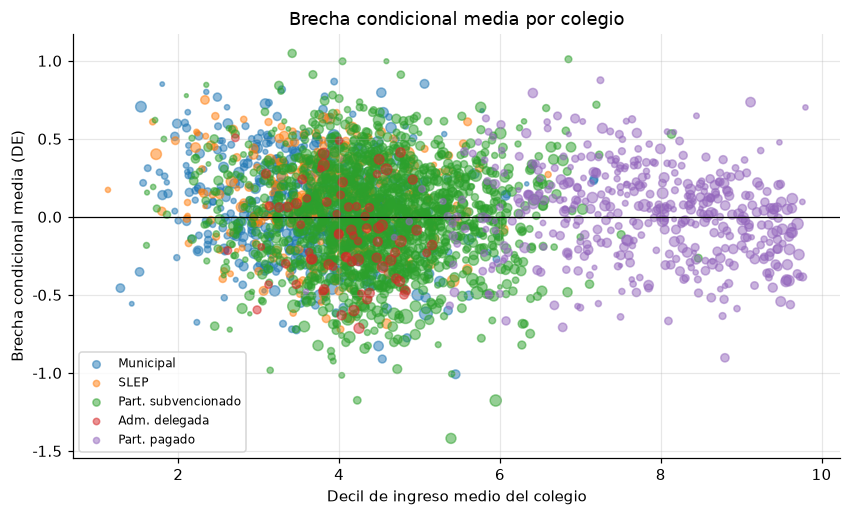

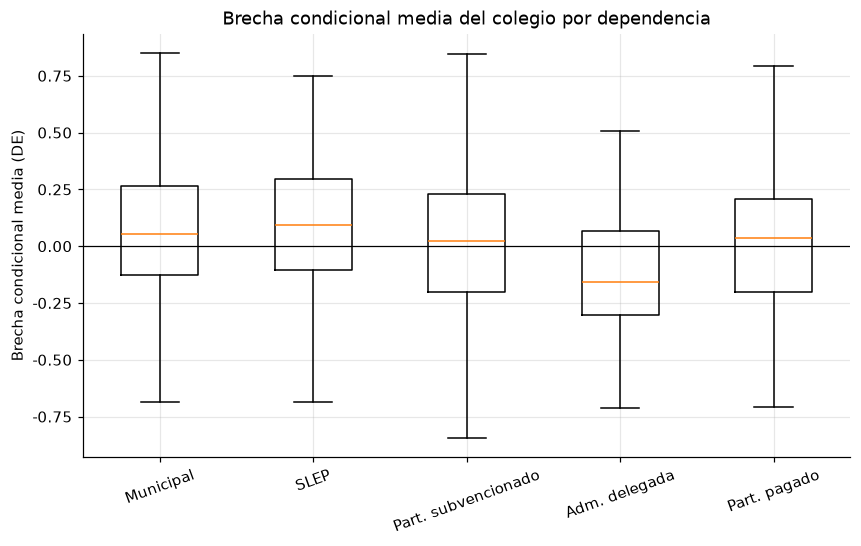

In [23]:
# 6.c Brecha condicional media de cada colegio (con al menos
# MIN_ESTUDIANTES_COLEGIO estudiantes): según su decil medio y por
# dependencia.
grandes = colegios[colegios['n'] >= MIN_ESTUDIANTES_COLEGIO]
fig, ax = plt.subplots()
for dependencia, grupo in grandes.groupby('dependencia', observed=True):
    ax.scatter(grupo['decil_medio'], grupo['brecha_cond_media'],
               s=np.sqrt(grupo['n']) * 2, alpha=0.5, label=dependencia)
ax.axhline(0, color='black', linewidth=0.8)
ax.set(title='Brecha condicional media por colegio',
       xlabel='Decil de ingreso medio del colegio',
       ylabel='Brecha condicional media (DE)')
ax.legend(markerscale=0.7, fontsize=8)
mostrar('eda_6c_dispersion')

fig, ax = plt.subplots()
boxplot_por_dependencia(ax, grandes, 'brecha_cond_media')
ax.set(title='Brecha condicional media del colegio por dependencia',
       ylabel='Brecha condicional media (DE)')
mostrar('eda_6c_boxplot')

## 7. Pregunta 3: brecha y etapas del acceso

Etapas: **postuló** (aparece en PS), **postulación válida** (selección o espera),
**seleccionado** (estado 24 o 26) y **matriculado** (aparece en M). NEM y PAES entran
al puntaje ponderado, así que parte de la asociación brecha-acceso es mecánica; 7.b
compara estudiantes con PAES similar.

,n,postuló,válida,seleccionado,matriculado,matric. | seleccionado
dependencia,,,,,,
Municipal,164087,61.6,58.1,48.7,41.8,79.2
SLEP,37375,59.6,55.4,47.4,42.5,81.4
Part. subvencionado,350115,67.3,65.0,54.4,45.4,77.9
Adm. delegada,21187,48.0,44.7,37.2,31.5,75.1
Part. pagado,81378,86.3,85.9,78.5,68.6,83.6


,n,postuló,válida,seleccionado,matriculado,matric. | seleccionado
decil,,,,,,
1,95405,63.4,59.8,49.2,42.3,78.9
2,72012,66.3,63.4,52.8,44.9,79.0
3,50302,67.8,65.3,55.2,47.0,79.7
4,41755,68.9,66.5,56.6,47.7,79.1
5,33486,68.7,66.5,56.7,47.6,78.7
6,33642,67.9,65.4,55.8,47.0,78.9
7,39877,65.3,62.7,53.1,44.5,78.0
8,44945,65.9,63.4,53.6,44.8,77.9
9,34524,71.3,69.5,60.7,50.9,79.0


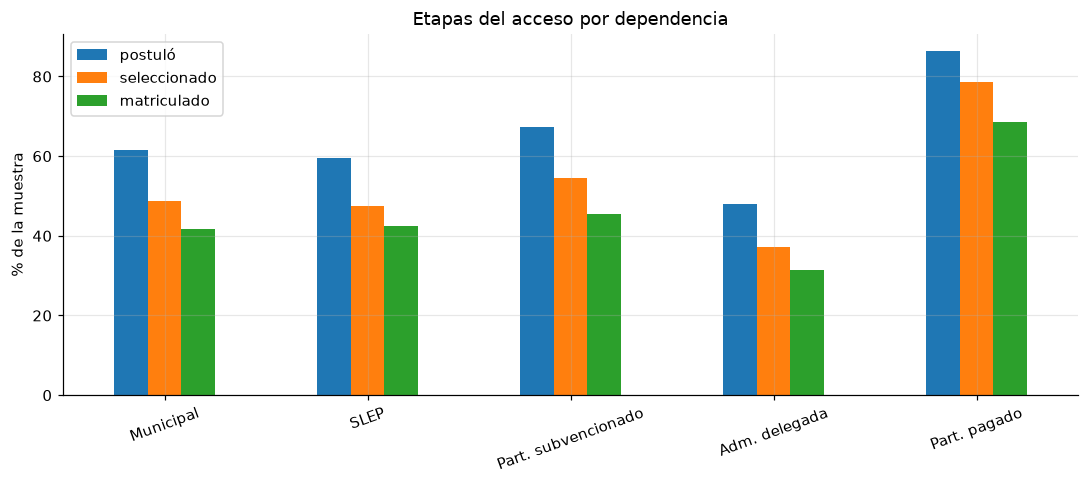

In [24]:
# 7.a Tasas por etapa (%) según dependencia y decil, y gráfico por
# dependencia.
tasas_dependencia = tasas_acceso(muestra, 'dependencia')
display(tasas_dependencia)
display(tasas_acceso(muestra, 'decil'))

ax = tasas_dependencia[['postuló', 'seleccionado', 'matriculado']].plot(
    kind='bar', rot=20, figsize=(10, 4.5))
ax.set(title='Etapas del acceso por dependencia', xlabel='',
       ylabel='% de la muestra')
plt.tight_layout()
mostrar('eda_7a')

% matriculado (toda la muestra):


tercil_paes,PAES baja,PAES media,PAES alta
quintil_brecha,,,
Q1,10.9,28.1,59.7
Q2,17.6,39.4,69.9
Q3,23.9,46.9,71.4
Q4,31.7,53.5,70.9
Q5,45.4,61.0,70.9


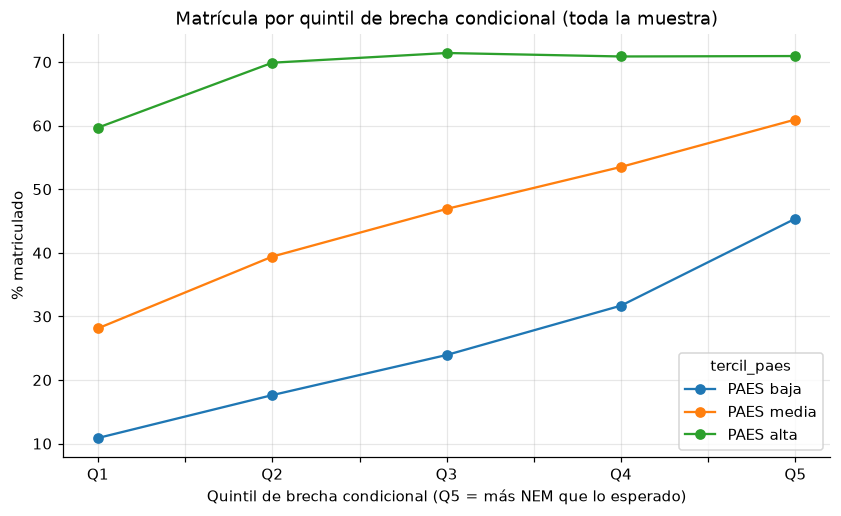

% matriculado (solo quienes postularon):


tercil_paes,PAES baja,PAES media,PAES alta
quintil_brecha,,,
Q1,32.2,50.1,74.2
Q2,39.8,59.4,79.1
Q3,47.3,65.7,79.3
Q4,55.2,70.3,78.4
Q5,68.6,75.8,79.2


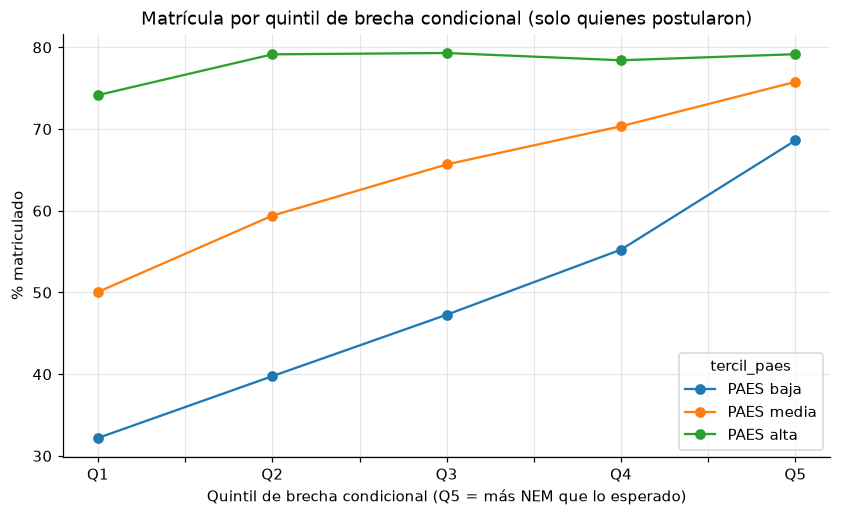

In [25]:
# 7.b Matrícula según quintil de brecha condicional, dentro de terciles de
# PAES. Si la tasa cambia con la brecha a igual PAES, la asociación no se
# explica solo por el nivel de PAES.
muestra['quintil_brecha'] = pd.qcut(muestra['brecha_cond'], 5,
                                    labels=['Q1', 'Q2', 'Q3', 'Q4', 'Q5'])
for nombre, titulo, datos in [
        ('muestra', 'toda la muestra', muestra),
        ('postulantes', 'solo quienes postularon',
         muestra[muestra['postulo']])]:
    tasas = 100 * datos.pivot_table(index='quintil_brecha',
                                    columns='tercil_paes',
                                    values='matriculado', aggfunc='mean',
                                    observed=True)
    print(f'% matriculado ({titulo}):')
    display(tasas.round(1))
    ax = tasas.plot(marker='o')
    ax.set(title=f'Matrícula por quintil de brecha condicional ({titulo})',
           xlabel='Quintil de brecha condicional (Q5 = más NEM que lo '
                  'esperado)',
           ylabel='% matriculado')
    mostrar(f'eda_7b_{nombre}')

## 8. Evolución 2023-2026

La brecha es relativa a cada año (media 0 por proceso): si la de un grupo baja,
puede ser porque el NEM de los otros sube más. Para niveles absolutos se usan las
variables sin estandarizar. Con cuatro años esto describe el periodo, no una
tendencia de largo plazo.

In [26]:
# 8.a Niveles absolutos por año y, por dependencia, el % con promedio de
# 6,0 o más y la brecha condicional media. La columna vale 100 si el
# promedio es >= 6,0 y 0 si no, así que su media es directamente un %.
muestra['pct_promedio_6'] = 100 * (muestra['PROMEDIO_NOTAS'] >= 6.0)
display(muestra.groupby('ANIO')[['PROMEDIO_NOTAS', 'pct_promedio_6',
                                 'PTJE_NEM', 'CLEC_1ra', 'MATE1_1ra']]
        .mean().round(2))

pct_6 = muestra.pivot_table(index='dependencia', columns='ANIO',
                            values='pct_promedio_6', aggfunc='mean',
                            observed=True)
pct_6['cambio 2023-2026'] = pct_6[2026] - pct_6[2023]
print('% con promedio >= 6,0 por dependencia y año:')
display(pct_6.round(1))
print('Brecha condicional media por dependencia y año:')
display(muestra.pivot_table(index='dependencia', columns='ANIO',
                            values='brecha_cond', aggfunc='mean',
                            observed=True).round(3))

,PROMEDIO_NOTAS,pct_promedio_6,PTJE_NEM,CLEC_1ra,MATE1_1ra
ANIO,,,,,
2023,6.03,54.93,723.01,640.15,560.81
2024,6.06,56.96,730.74,595.45,602.40
2025,6.06,57.17,731.19,592.49,624.71
2026,6.09,59.22,738.00,607.09,632.22


% con promedio >= 6,0 por dependencia y año:


ANIO,2023,2024,2025,2026,cambio 2023-2026
dependencia,,,,,
Municipal,51.3,52.3,53.8,56.8,5.5
SLEP,51.1,51.3,54.5,57.1,6.1
Part. subvencionado,52.3,55.1,54.8,56.3,4.0
Adm. delegada,35.6,38.8,43.1,49.9,14.3
Part. pagado,81.1,82.2,79.2,79.0,-2.1


Brecha condicional media por dependencia y año:


ANIO,2023,2024,2025,2026
dependencia,,,,
Municipal,0.030,0.022,0.056,0.079
SLEP,0.119,0.076,0.140,0.128
Part. subvencionado,-0.029,-0.014,-0.024,-0.033
Adm. delegada,-0.215,-0.194,-0.105,0.012
Part. pagado,0.083,0.041,-0.041,-0.092


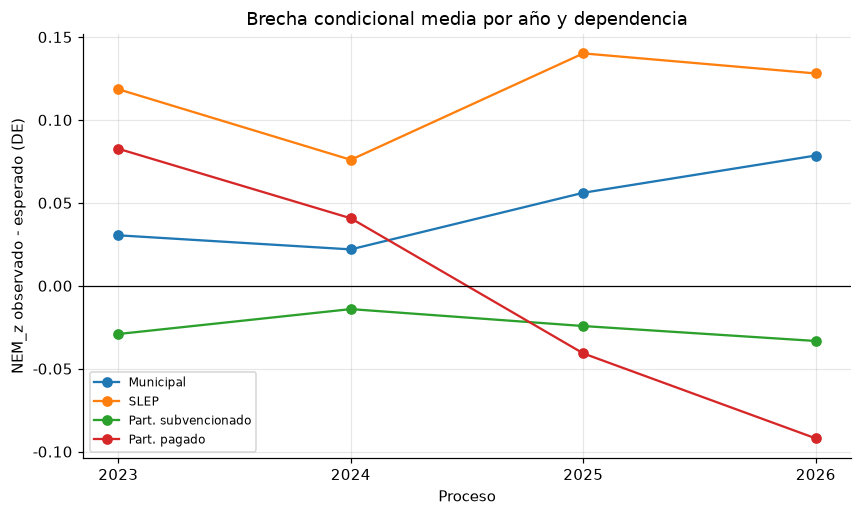

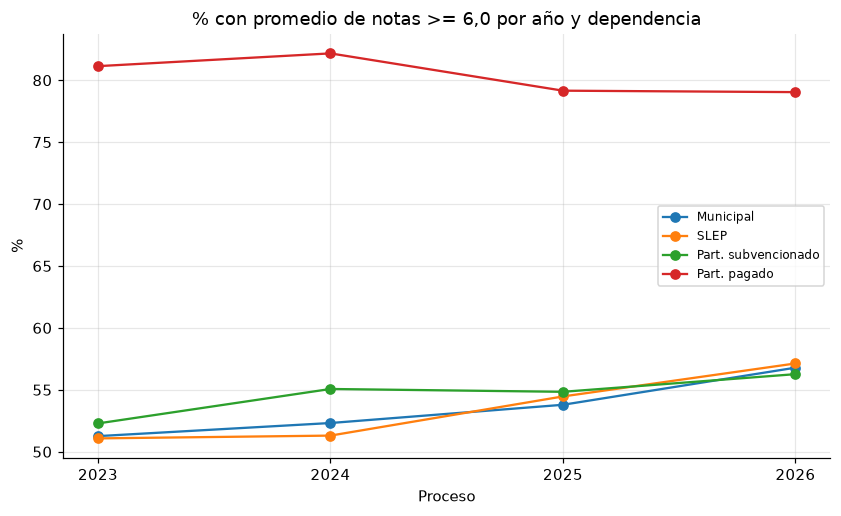

In [27]:
# 8.b Brecha condicional y % con promedio >= 6,0 por año y dependencia.
fig, ax = plt.subplots()
lineas_por_dependencia(ax, muestra, 'ANIO', 'brecha_cond')
ax.axhline(0, color='black', linewidth=0.8)
ax.set(title='Brecha condicional media por año y dependencia',
       xlabel='Proceso', ylabel='NEM_z observado - esperado (DE)')
mostrar('eda_8b_brecha')

fig, ax = plt.subplots()
lineas_por_dependencia(ax, muestra, 'ANIO', 'pct_promedio_6')
ax.set(title='% con promedio de notas >= 6,0 por año y dependencia',
       xlabel='Proceso', ylabel='%')
mostrar('eda_8b_promedio6')

In [28]:
# Guarda la muestra para el modelamiento (data/processed/ en .gitignore).
muestra[COLUMNAS_MUESTRA].to_parquet(ARCHIVO_MUESTRA, index=False)
print(f'Guardado {ARCHIVO_MUESTRA.name}: {len(muestra)} estudiantes, '
      f'{len(COLUMNAS_MUESTRA)} columnas')

Guardado muestra.parquet: 654142 estudiantes, 25 columnas


## 9. Síntesis de hallazgos del EDA

Resultados descriptivos (asociaciones, no relaciones causales), en desviaciones
estándar (DE) dentro de cada año y electiva. Medida principal: brecha condicional.

**Calidad y muestra**

- Panel de 1.240.008 inscritos; muestra de **654.142 estudiantes** (278.579 solo
  Ciencias, 191.484 Ambas y 184.079 solo Historia). El filtro que más elimina es el
  egreso reciente (unos 405 mil); luego no rendir electiva (unos 136 mil) y no venir
  de la educación regular en un establecimiento identificado (27.791).
- Códigos confirmados con los libros de códigos 2026. Seleccionado = estado 24 o 26;
  la postulación válida coincide en el 100% con `SITUACION_POSTULANTE` (2023).
- Un 0 en la PAES es "no rindió"; casi nadie rinde en invierno ni en el proceso
  anterior (1.c). El 25,9% no declara ingreso (categoría propia) y solo el 0,2% tiene
  el NEM máximo.

**Pregunta 1: NEM y PAES**

- Correlación moderada y estable: entre 0,56 y 0,58 con Ciencias, 0,49 y 0,51 con
  Historia y 0,48 y 0,49 en Ambas. Por eso hay regresión a la media y se usa la
  brecha condicional.
- Electiva, Lectora y Matemática 1 ordenan igual a las dependencias, y la conversión
  de notas a NEM es la misma en HC y TP (4.e).

**Pregunta 2: dependencia y nivel socioeconómico**

| Dependencia | n | NEM_z | PAES_z | Brecha condicional | Brecha simple |
|---|---:|---:|---:|---:|---:|
| Municipal | 164.087 | -0,090 | -0,256 | 0,045 | 0,166 |
| SLEP | 37.375 | -0,078 | -0,378 | 0,120 | 0,300 |
| Part. subvencionado | 350.115 | -0,062 | -0,067 | -0,025 | 0,005 |
| Adm. delegada | 21.187 | -0,377 | -0,476 | -0,126 | 0,099 |
| Part. pagado | 81.378 | 0,582 | 1,103 | -0,005 | -0,521 |

- A igual PAES, las dependencias tienen un NEM muy parecido (entre -0,13 y +0,12);
  las diferencias de la brecha simple vienen de la PAES.
- **SLEP** es la excepción: entre +0,08 y +0,18 en todos los deciles y en los tres
  grupos de electiva. Adm. delegada está en el otro extremo (-0,13).
- El decil casi no cambia la brecha condicional (entre -0,04 y +0,05), y la
  diferencia por modalidad desaparece (técnico-profesional -0,05). La de **sexo** se
  mantiene: mujeres +0,18 y hombres -0,20.
- Dependencia y decil se asocian (V de Cramér = 0,265): revisar colinealidad.

**Nivel colegio**

- 3.034 colegios (mediana de 171 estudiantes); 202 cambian de dependencia.
- Proporción de varianza entre colegios (4 años): brecha condicional 0,14 (cerca de
  0,17 en cada año), NEM_z 0,16, PAES_z 0,33. Justifica el modelo jerárquico con
  efecto aleatorio por colegio.

**Pregunta 3: acceso**

- Las diferencias están en postular (de 48% en Adm. delegada a 86% en Part. pagado)
  y quedar seleccionado (de 37% a 79%); ya seleccionados, se matricula entre 75% y
  84%.
- A igual PAES, más brecha condicional se asocia a más matrícula, sobre todo con PAES
  baja (de 11% a 45%; de 32% a 69% entre postulantes). Parte es mecánica: el NEM
  pondera en el puntaje.

**Evolución 2023-2026**

- El % con promedio de 6,0 o más sube de 54,9% a 59,2%; cuatro procesos no bastan
  para hablar de inflación de notas.
- La brecha condicional de Part. pagado baja de +0,08 a -0,09, pero es relativa: su %
  con promedio >= 6,0 casi no cambia (81,1% a 79,0%), mientras sube entre 4 y 14
  puntos en las demás dependencias.

**Decisiones para el modelamiento**

- Brecha condicional como medida principal; electiva como prueba de referencia
  (Lectora y M1 como sensibilidad); rendición regular; grupo Ambas incluido.
- Nivel estudiante: PAES_z, decil, sexo y año; nivel colegio: dependencia,
  modalidad y composición socioeconómica; efecto aleatorio por RBD.
- Acceso por etapas con modelos logísticos, a igual PAES, usando el puntaje
  ponderado máximo para separar la parte mecánica.